<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/06_Survival_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SURVIVAL ANALYSIS**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install lifelines

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

# Load dataset
project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(
    project_path, 'data', 'telco_churn_feature_engineered.csv'
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df[['tenure', 'Churn']].head())

Dataset shape: (7043, 22)
   tenure Churn
0       1    No
1      34    No
2       2   Yes
3      45    No
4       2   Yes


### Prepare Survival Data

In [ ]:
# Create event indicator
df['Event'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Select survival analysis columns
survival_df = df[['tenure', 'Event']].copy()

print("Total customers:", len(survival_df))
print("Churned customers:", survival_df['Event'].sum())
print("Retained customers:", (survival_df['Event'] == 0).sum())

survival_df.head()

Total customers: 7043
Churned customers: 1869
Retained customers: 5174


,tenure,Event
0,1,0
1,34,0
2,2,1
3,45,0
4,2,1


### Kaplan-Meier Survival Analysis

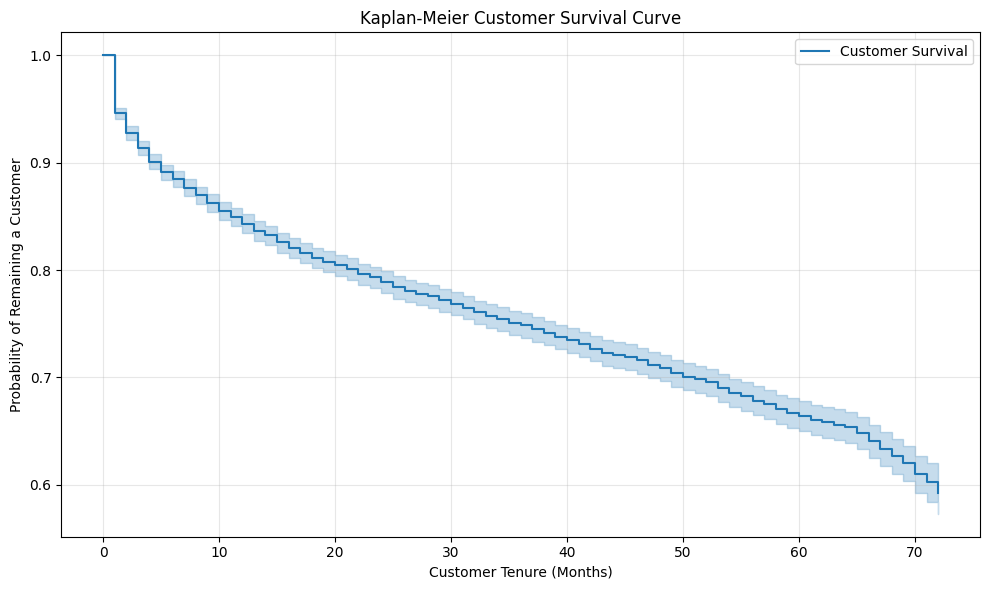

In [ ]:
# Initialize Kaplan-Meier estimator
kmf = KaplanMeierFitter()

# Fit the survival model
kmf.fit(
    durations=survival_df['tenure'],
    event_observed=survival_df['Event'],
    label='Customer Survival'
)

# Plot survival curve
plt.figure(figsize=(10, 6))

kmf.plot_survival_function()

plt.title('Kaplan-Meier Customer Survival Curve')
plt.xlabel('Customer Tenure (Months)')
plt.ylabel('Probability of Remaining a Customer')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Calculate Exact survival probabilities

In [ ]:
# Calculate survival probability at selected months

months = [6, 12, 24, 36, 48, 60, 72]

survival_probabilities = kmf.survival_function_at_times(months)

survival_summary = pd.DataFrame({
    'Month': months,
    'Survival Probability': survival_probabilities.values
})

survival_summary['Survival Percentage'] = (
    survival_summary['Survival Probability'] * 100
).round(2)

survival_summary

,Month,Survival Probability,Survival Percentage
0,6,0.884826,88.48
1,12,0.843200,84.32
2,24,0.788736,78.87
3,36,0.748545,74.85
4,48,0.708840,70.88
5,60,0.664404,66.44
6,72,0.592790,59.28


### Survival Analysis by contract type

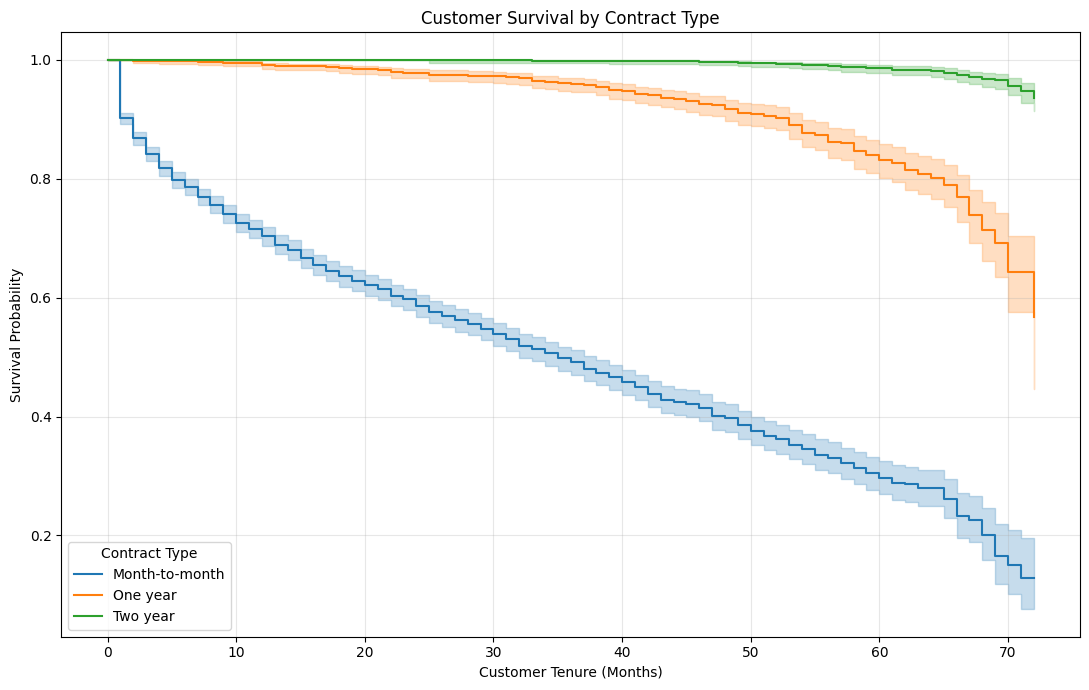

In [ ]:
plt.figure(figsize=(11, 7))

for contract in df['Contract'].unique():

    contract_data = df[df['Contract'] == contract]

    kmf_contract = KaplanMeierFitter()

    kmf_contract.fit(
        durations=contract_data['tenure'],
        event_observed=contract_data['Event'],
        label=contract
    )

    kmf_contract.plot_survival_function()

plt.title('Customer Survival by Contract Type')
plt.xlabel('Customer Tenure (Months)')
plt.ylabel('Survival Probability')

plt.grid(alpha=0.3)
plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

### Cox Proportional Hazards Model

In [ ]:
from lifelines import CoxPHFitter

# Select relevant features
cox_df = df[
    [
        'tenure',
        'Event',
        'MonthlyCharges',
        'SeniorCitizen',
        'Contract',
        'InternetService',
        'OnlineSecurity',
        'TechSupport'
    ]
].copy()

# Encode categorical variables
cox_df = pd.get_dummies(
    cox_df,
    columns=[
        'Contract',
        'InternetService',
        'OnlineSecurity',
        'TechSupport'
    ],
    drop_first=True,
    dtype=int
)

# Remove tenure as a predictor because it is also our duration variable
cox_df = cox_df.drop(columns=['tenure'])

print("Cox dataset shape:", cox_df.shape)
print(cox_df.head())

Cox dataset shape: (7043, 11)
   Event  MonthlyCharges  SeniorCitizen  Contract_One year  Contract_Two year  \
0      0           29.85              0                  0                  0   
1      0           56.95              0                  1                  0   
2      1           53.85              0                  0                  0   
3      0           42.30              0                  1                  0   
4      1           70.70              0                  0                  0   

   InternetService_Fiber optic  InternetService_No  \
0                            0                   0   
1                            0                   0   
2                            0                   0   
3                            0                   0   
4                            1                   0   

   OnlineSecurity_No internet service  OnlineSecurity_Yes  \
0                                   0                   0   
1                                   

### Train The cox Model

In [ ]:
# Remove redundant dummy variables
cox_model_df = cox_model_df.drop(
    columns=[
        'OnlineSecurity_No internet service',
        'TechSupport_No internet service'
    ]
)

print("Updated shape:", cox_model_df.shape)

Updated shape: (7043, 10)


In [ ]:
cph = CoxPHFitter(penalizer=0.1)

cph.fit(
    cox_model_df,
    duration_col='tenure',
    event_col='Event'
)

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'tenure'
                event col = 'Event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -14686.55
         time fit was run = 2026-11-16 12:01:04 UTC

---
                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                    
MonthlyCharges              -0.00      1.00      0.00           -0.01           -0.00                0.99                1.00
SeniorCitizen                0.03      1.03      0.05           -0.06            0.13                0.94                1.13
Contract_One year           -1.01      0.36      0.05           -1.12           -0.91                0.33                0.40
Contract_Two year           -1.48      0.23      0.06           -1.59           -1.36                0.20                0.26
InternetService_Fiber optic  0.40      1.49      0.05            0.30            0.50                1.35                1.65
InternetService_No          -0.64      0.53      0.07           -0.77           -0.51                0.46                0.60
OnlineSecurity_Yes          -0.57      0.56      0.05           -0.67           -0.48                0.51                0.62
TechSupport_Yes             -0.47      0.63      0.05           -0.57           -0.37                0.57                0.69

                             cmp to      z      p  -log2(p)
covariate                                                  
MonthlyCharges                 0.00  -3.38 <0.005     10.42
SeniorCitizen                  0.00   0.63   0.53      0.92
Contract_One year              0.00 -18.58 <0.005    253.64
Contract_Two year              0.00 -24.63 <0.005    442.70
InternetService_Fiber optic    0.00   7.77 <0.005     46.91
InternetService_No             0.00  -9.57 <0.005     69.65
OnlineSecurity_Yes             0.00 -11.70 <0.005    102.61
TechSupport_Yes                0.00  -9.47 <0.005     68.26
---
Concordance = 0.83
Partial AIC = 29389.11
log-likelihood ratio test = 1932.97 on 8 df
-log2(p) of ll-ratio test = inf

In [ ]:
from lifelines import CoxPHFitter

cph = CoxPHFitter(penalizer=0.1)

cph.fit(
    cox_model_df,
    duration_col='tenure',
    event_col='Event'
)

print("Cox model fitted successfully!")

Cox model fitted successfully!



   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'MonthlyCharges' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'MonthlyCharges' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'MonthlyCharges' using pd.cut, and then specify it in
`strata=['MonthlyCharges', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


2. Variable 'Contract_One year' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_One year', ...]`
in the call in `.fit`. See documentat

[[<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0975)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1201)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0001)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1075)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1560)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6014)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5996)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0349)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0580)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0066)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0127)'>]]

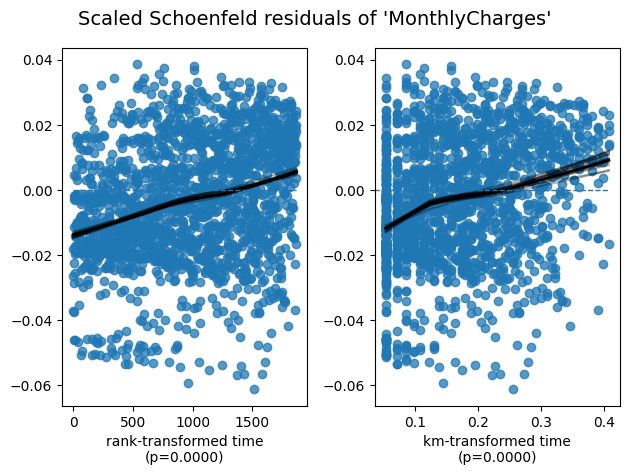

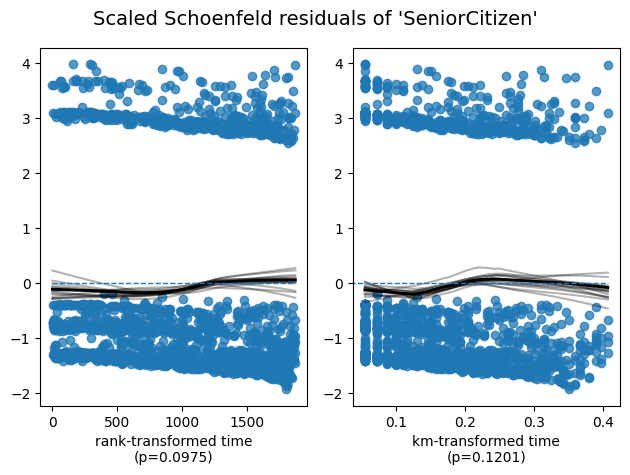

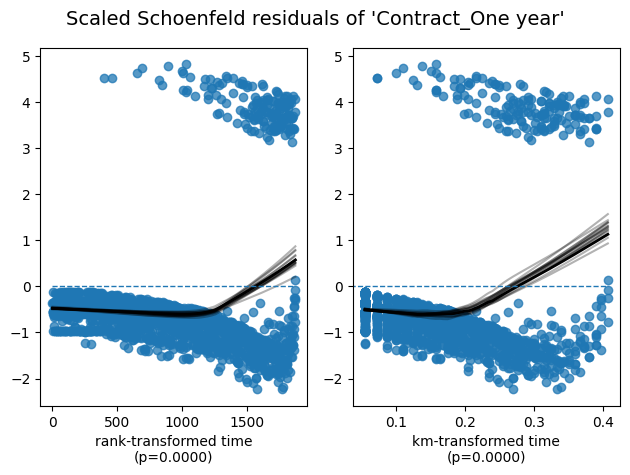

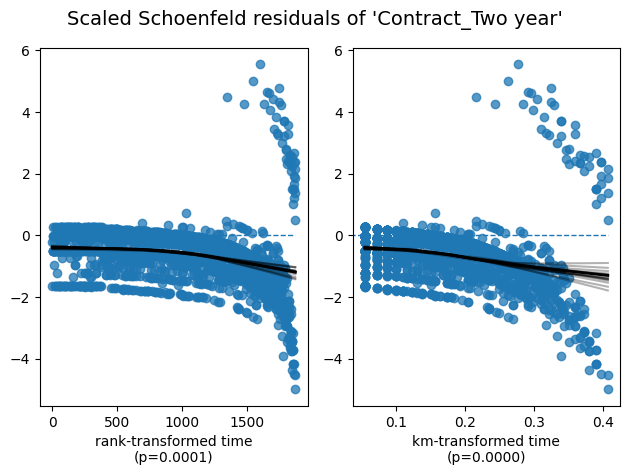

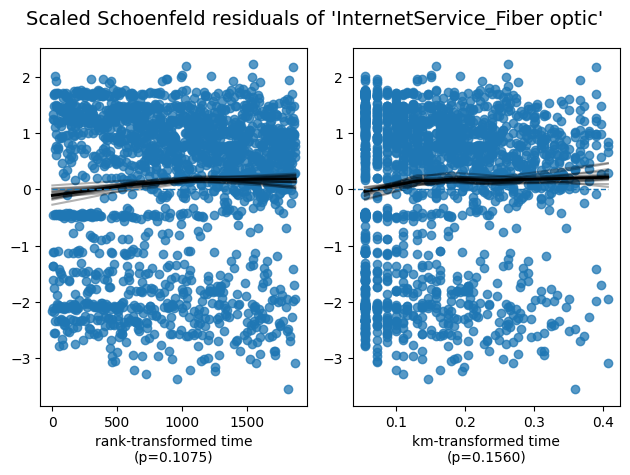

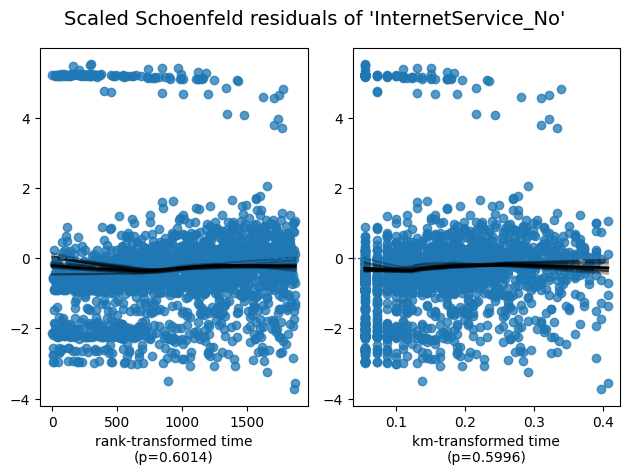

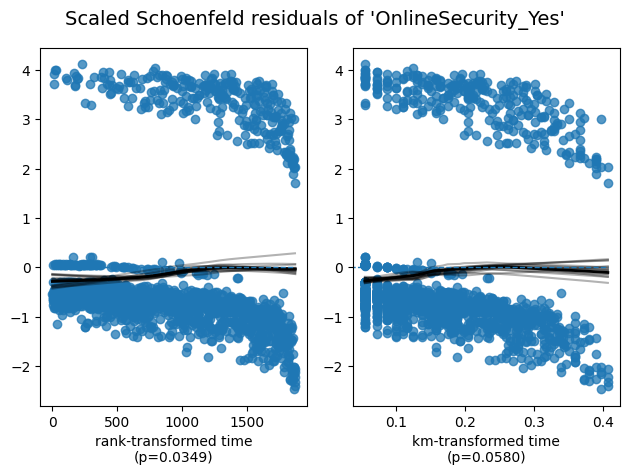

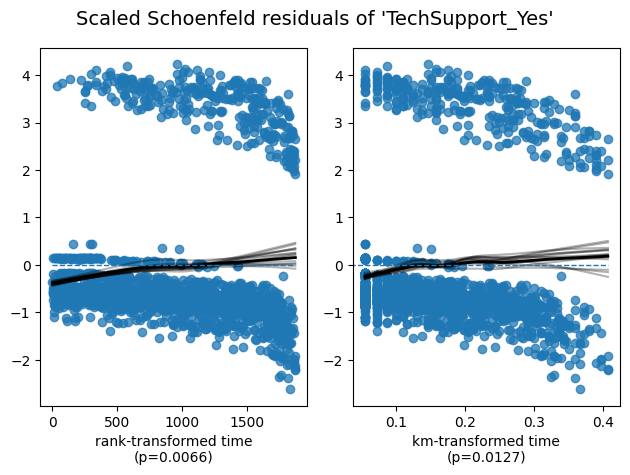

In [ ]:
cph.check_assumptions(
    cox_model_df,
    p_value_threshold=0.05,
    show_plots=True
)

### Save the COX Model and results

In [ ]:
import joblib
import os

models_path = os.path.join(project_path, 'models')
os.makedirs(models_path, exist_ok=True)

# Save Cox model
joblib.dump(
    cph,
    os.path.join(models_path, 'cox_survival_model.pkl')
)

# Save hazard ratio summary
cph.summary.to_csv(
    os.path.join(
        project_path,
        'documentation',
        'cox_hazard_ratios.csv'
    )
)

print("Cox model saved successfully!")
print("Hazard ratio results saved successfully!")

Cox model saved successfully!
Hazard ratio results saved successfully!
